<p align="center">
  <span style="color:Navy; font-size:200%; font-weight:bold; vertical-align:middle;">
    Temas Selectos: Python para Ciencias de la Tierra
  </span>
</p>
    
# <font color="purple"> **Análisis espacial: GeoPandas**</font>


---



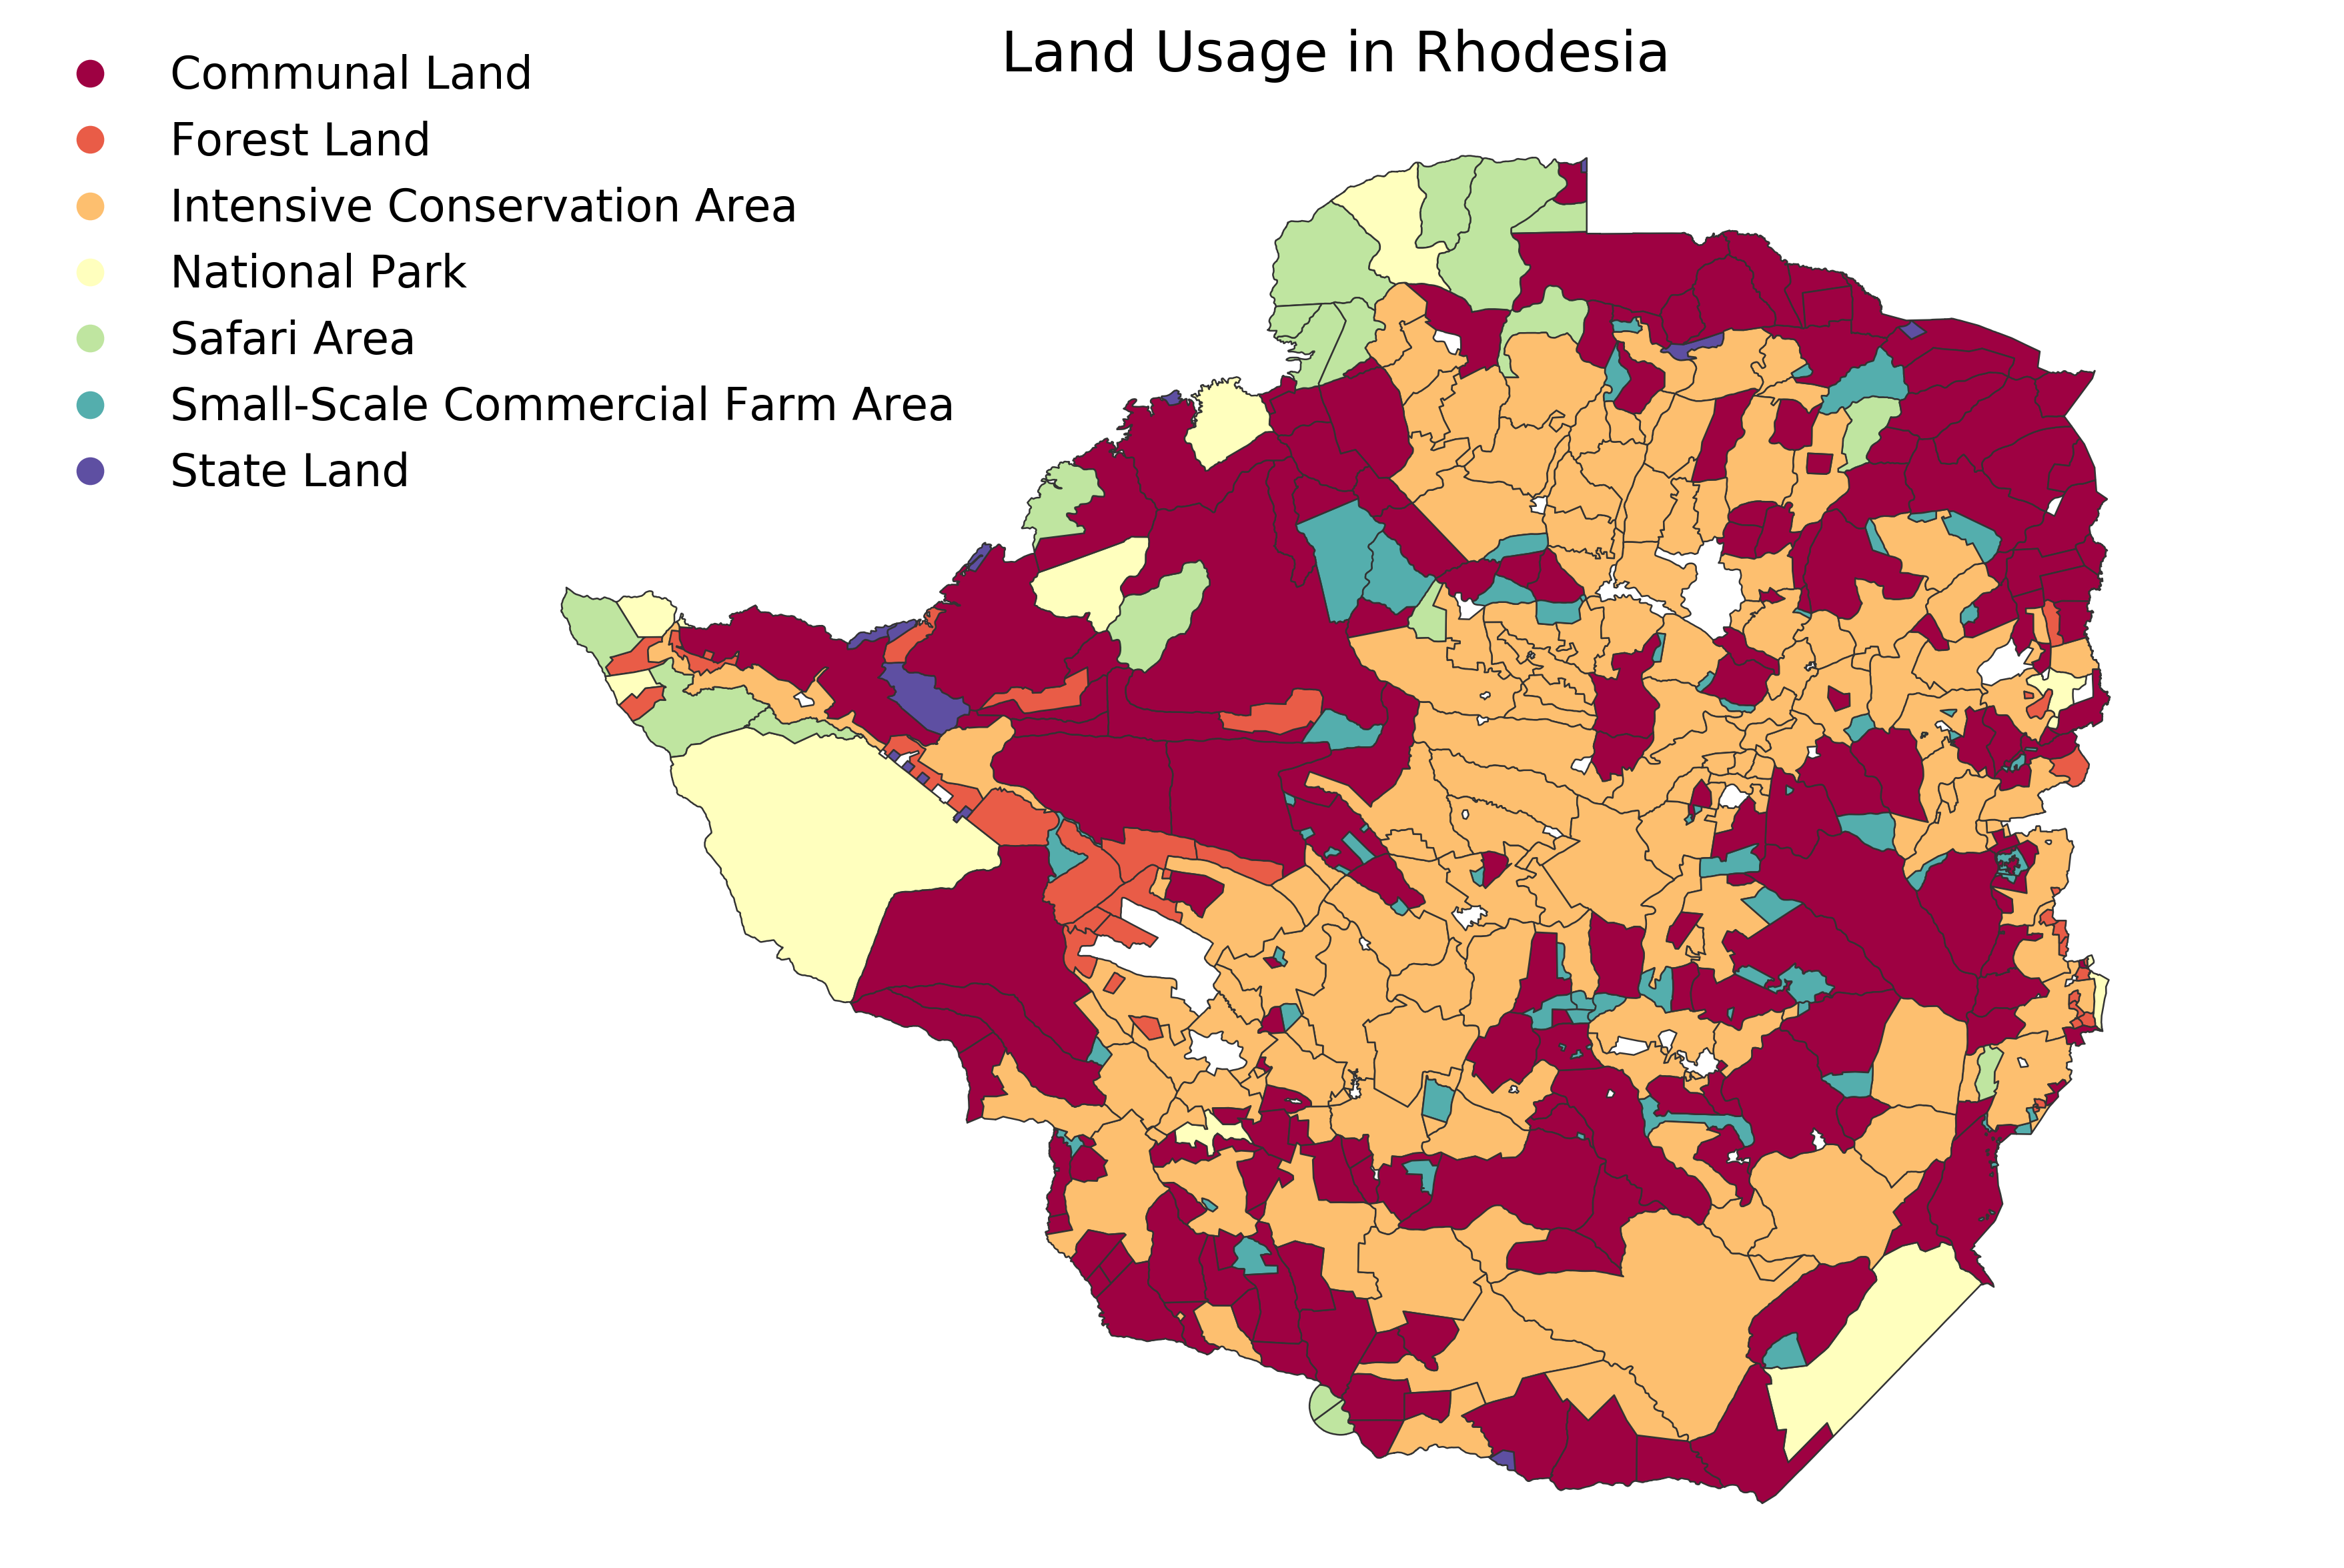

### ¿Por qué usar GeoPandas en Ciencias de la Tierra?
`GeoPandas` extiende pandas para trabajar con **datos espaciales vectoriales** (puntos, líneas y polígonos) en un mismo DataFrame que conoce su **sistema de referencia de coordenadas (CRS)**. Esto nos permite analizar y mapear fenómenos ambientales y geofísicos con un flujo de trabajo claro y reproducible (<https://geopandas.org/en/latest/index.html>).

Beneficios clave:
- Une *atributos tabulares* (como en pandas) con *geometrías* y *CRS* en una sola estructura (GeoDataFrame).
- Soporta operaciones espaciales comunes: *join espacial* (¿en qué polígono cae un punto?)
- Calcula *áreas y longitudes* correctamente al reproyectar a un CRS adecuado (p. ej., igual-área).
- Lee y escribe formatos estándar: *Shapefile*, *GeoJSON*, *GeoPackage*, entre otros.
- Se integra con *NumPy/pandas* para estadísticas y con *Matplotlib* para mapas rápidos (coropletas, capas superpuestas).
- Favorece la **reproducibilidad**: mismo código + mismos datos ⇒ mismo resultado/cartografía.

Ejemplos típicos en el curso:
- Asignar **estaciones** a **municipios/cuencas** (join espacial) y resumir promedios por polígono.
- Construir **zonas de influencia** (buffers) alrededor de pozos, sensores o fuentes de emisión.
- **Recortar** capas a un área de estudio y **disolver** límites por categoría (e.g., continente, ecorregión).
- Elaborar **mapas temáticos** con leyendas claras y escalas consistentes.


In [1]:
pip install geodatasets

  Using cached geodatasets-2026.5.1-py3-none-any.whl.metadata (5.5 kB)
  Using cached pooch-1.9.0-py3-none-any.whl.metadata (10 kB)
Using cached geodatasets-2026.5.1-py3-none-any.whl (21 kB)
Using cached pooch-1.9.0-py3-none-any.whl (67 kB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
import geopandas as gpd
import geodatasets as gd
import pandas as pd
import matplotlib.pyplot as plt

### ¿Qué es *geodatasets*?

`geodatasets` es un paquete en Python que provee acceso rápido a **conjuntos de datos geoespaciales de ejemplo**.  
Fue creado para complementar librerías como **GeoPandas**, ofreciendo datos ya listos para usar en prácticas, demos y clases (<https://geodatasets.readthedocs.io/en/stable/introduction.html>).

---

### ¿Por qué usarlo?

- Permite **cargar datos reales** de manera sencilla sin tener que buscarlos ni descargarlos manualmente.  
- Incluye datos comunes en análisis geográficos: límites de países, ciudades, placas tectónicas, cuencas hidrográficas, etc.  
- Es ideal para **ejercicios de aprendizaje**, ya que los archivos son livianos y estandarizados.  

---

### Ejemplo de uso básico

```python
import geopandas as gpd
import geodatasets

# Listar datasets disponibles
geodatasets.data

# Cargar límites mundiales de Natural Earth
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))


In [3]:
# Ejemplos reales incluidos:
NY  = gpd.read_file(gd.get_path("ny.bb"))  # por ejemplo, NY Boroughs (polígonos)
# También hay otros (ver docs de geodatasets)
NY

,BoroCode,BoroName,Shape_Leng,Shape_Area,geometry
0,5,Staten Island,330470.010332,1.623820e+09,"MULTIPOLYGON (((970217.022 145643.332, 970227...."
1,4,Queens,896344.047763,3.045213e+09,"MULTIPOLYGON (((1029606.077 156073.814, 102957..."
2,3,Brooklyn,741080.523166,1.937479e+09,"MULTIPOLYGON (((1021176.479 151374.797, 102100..."
3,1,Manhattan,359299.096471,6.364715e+08,"MULTIPOLYGON (((981219.056 188655.316, 980940...."
4,2,Bronx,464392.991824,1.186925e+09,"MULTIPOLYGON (((1012821.806 229228.265, 101278..."


In [4]:
gd.data

{'geoda': {'airbnb': {'url': 'https://geodacenter.github.io/data-and-lab//data/airbnb.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.airbnb',
   'description': 'Airbnb rentals, socioeconomics, and crime in Chicago',
   'geometry_type': 'Polygon',
   'nrows': 77,
   'ncols': 21,
   'details': 'https://geodacenter.github.io/data-and-lab//airbnb/',
   'hash': 'a2ab1e3f938226d287dd76cde18c00e2d3a260640dd826da7131827d9e76c824',
   'filename': 'airbnb.zip'},
  'atlanta': {'url': 'https://geodacenter.github.io/data-and-lab//data/atlanta_hom.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.atlanta',
   'description': 'Atlanta, GA region homicide counts and rates',
   'geometry_type': 'Polygon',
   'nrows': 90,
   'ncols': 24,
   'details': 'https://geodacenter.github.io/data-and-lab//atlanta_old/',
   'hash': 'a33a76e12168fe84361e60c88a9df4856730487305846c559715c89b1a2b5e09',
   'filename': 'atlanta_hom.zip',
   'members': ['atlanta_hom/atl_hom.geojson']},
  'cars': {'url': 'https://geodacenter.github.io/data-and-lab//data/Abandoned_Vehicles_Map.csv',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.cars',
   'description': '2011 abandoned vehicles in Chicago (311 complaints).',
   'geometry_type': 'Point',
   'nrows': 137867,
   'ncols': 21,
   'details': 'https://geodacenter.github.io/data-and-lab//1-source-and-description/',
   'hash': '6a0b23bc7eda2dcf1af02d43ccf506b24ca8d8c6dc2fe86a2a1cc051b03aae9e',
   'filename': 'Abandoned_Vehicles_Map.csv'},
  'charleston1': {'url': 'https://geodacenter.github.io/data-and-lab//data/CharlestonMSA.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.charleston1',
   'description': '2000 Census Tract Data for Charleston, SC MSA and counties',
   'geometry_type': 'Polygon',
   'nrows': 117,
   'ncols': 31,
   'details': 'https://geodacenter.github.io/data-and-lab//charleston-1_old/',
   'hash': '4a4fa9c8dd4231ae0b2f12f24895b8336bcab0c28c48653a967cffe011f63a7c',
   'filename': 'CharlestonMSA.zip',
   'members': ['CharlestonMSA/sc_final_census2.gpkg']},
  'charleston2': {'url': 'https://geodacenter.github.io/data-and-lab//data/CharlestonMSA2.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.charleston2',
   'description': '1998 and 2001 Zip Code Business Patterns (Census Bureau) for Charleston, SC MSA',
   'geometry_type': 'Polygon',
   'nrows': 42,
   'ncols': 60,
   'details': 'https://geodacenter.github.io/data-and-lab//charleston2/',
   'hash': '056d5d6e236b5bd95f5aee26c77bbe7d61bd07db5aaf72866c2f545205c1d8d7',
   'filename': 'CharlestonMSA2.zip',
   'members': ['CharlestonMSA2/CharlestonMSA2.gpkg']},
  'chicago_health': {'url': 'https://geodacenter.github.io/data-and-lab//data/comarea.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.chicago_health',
   'description': 'Chicago Health + Socio-Economics',
   'geometry_type': 'Polygon',
   'nrows': 77,
   'ncols': 87,
   'details': 'https://geodacenter.github.io/data-and-lab//comarea_vars/',
   'hash': '4e872adb552786eae2fcd745524696e5e4cd33cc9a6c032471c0e75328871401',
   'filename': 'comarea.zip'},
  'chicago_commpop': {'url': 'https://geodacenter.github.io/data-and-lab//data/chicago_commpop.zip',
   'license': 'NA',
   'attribution': 'Center for Spatial Data Science, University of Chicago',
   'name': 'geoda.chicago_commpop',
   'description': 'Chicago Community Area Population Percent Change for 2000 and 2010',
   'geometry_type': 'Polygon',
   'nrows': 77,
   'ncols': 9,
   'details': 'https://geodacenter.github.io/data-and-lab//commpop/',
   'hash': '1dbebb50c8ea47e2279ea819ef64ba793bdee2b88e4716bd6c6ec0e0d8e0e05b',
   'filename': 'c

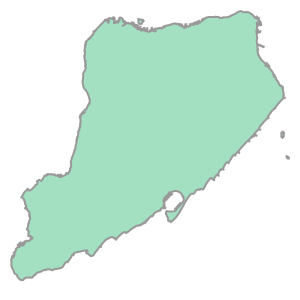

In [5]:
#Vamos a ver lo que guarda la columna geometry
NY.geometry[0]

In [6]:
#¿Cómo observamos el sistema de referencia de las coordenadas? <https://geopandas.org/en/latest/docs/user_guide/projections.html>
NY.crs

<Projected CRS: EPSG:2263>
Name: NAD83 / New York Long Island (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - New York - counties of Bronx; Kings; Nassau; New York; Queens; Richmond; Suffolk.
- bounds: (-74.26, 40.47, -71.8, 41.3)
Coordinate Operation:
- name: SPCS83 New York Long Island zone (US survey foot)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

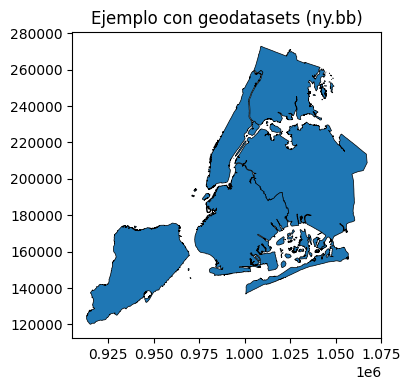

In [7]:
ax = NY.plot(edgecolor="black", linewidth=0.5, figsize=(6,4))
ax.set_title("Ejemplo con geodatasets (ny.bb)")
plt.tight_layout()

### Descarga y uso de datos espaciales desde Natural Earth

En lugar de usar archivos locales, también podemos leer **archivos vectoriales directamente desde una URL**.  
Natural Earth provee conjuntos de datos de uso libre en distintos niveles de detalle (1:110m, 1:50m, 1:10m).

---

#### 1. Cargar países y ciudades
```python
url_world  = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
url_cities = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_populated_places_simple.zip"

world  = gpd.read_file(url_world)
cities = gpd.read_file(url_cities)


In [8]:
url_world  = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
url_cities = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_populated_places_simple.zip"

world  = gpd.read_file(url_world)
cities = gpd.read_file(url_cities)

In [9]:
world.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [10]:
world.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


Seleccionamos solo el polígono de México usando la columna "ADMIN".

Convertimos su proyección a EPSG:4326 (latitud/longitud en grados), para asegurar compatibilidad.

[EPSG Geodetic Parameter Dataset](https://epsg.org/home.html).

Luego ajustamos las ciudades al mismo sistema de referencia espacial que México `to_crs`

Esto es esencial: todas las capas deben tener el mismo CRS para poder hacer operaciones espaciales.

In [11]:
# Filtrar México
mex = world[world["ADMIN"] == "Mexico"].to_crs("EPSG:4326")

# Asegurar mismo CRS y hacer join espacial (puntos dentro del polígono)
cities = cities.to_crs(mex.crs)
cities.head()

,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,...,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,8,10,3,Admin-0 capital,Vatican City,None,None,Vatican City,1,0,...,832,832,562430,2,2,None,Vatican City,7.0,1159127243,POINT (12.45339 41.90328)
1,7,20,0,Admin-0 capital,San Marino,None,None,San Marino,1,0,...,29579,29000,0,7,7,None,San Marino,6.1,1159146051,POINT (12.44177 43.9361)
2,7,20,0,Admin-0 capital,Vaduz,None,None,Vaduz,1,0,...,36281,5342,33009,7,5,None,Vaduz,6.7,1159146061,POINT (9.51667 47.13372)
3,6,30,8,Admin-0 capital alt,Lobamba,None,None,Lobamba,0,1,...,9782,4557,0,5,4,None,Lobamba,6.0,1159146343,POINT (31.2 -26.46667)
4,6,30,8,Admin-0 capital,Luxembourg,None,None,Luxembourg,1,0,...,107260,76684,106219,9,8,None,Luxembourg,6.0,1159146437,POINT (6.13 49.61166)


`sjoin` compara dos GeoDataFrames según su geometría.

Con predicate="within" seleccionamos únicamente las ciudades dentro de la geometría de México.

El resultado cities_mx es un subconjunto de ciudades filtradas por ubicación.

In [12]:
cities_mx = gpd.sjoin(cities, mex[["ADMIN","geometry"]], how="inner", predicate="within")
cities_mx

,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,...,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry,index_right,ADMIN
196,1,300,2,Admin-1 capital,Monterrey,None,None,Monterrey,0,0,...,3225636,12,12,Monterrey,Monterrey,3.7,1159151527,POINT (-100.33193 25.67194),27,Mexico
224,0,600,2,Admin-0 capital,Mexico City,None,Ciudad de M,Mexico City,1,0,...,10018444,14,14,Ciudad de Mdxico,Mexico City,2.1,1159151587,POINT (-99.13293 19.44439),27,Mexico


In [13]:
mex

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
27,Admin-0 country,1,2,Mexico,MEX,0,2,Sovereign country,1,Mexico,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-117.12776 32.53534, -115.99135 32.6..."


Ciudades encontradas en México: 2


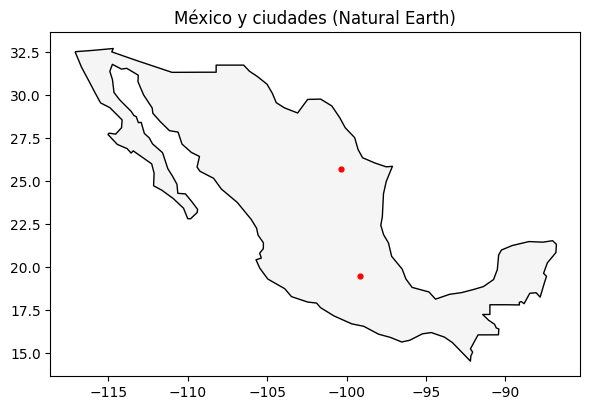

In [14]:
# Mapa rápido
ax = mex.plot(figsize=(6,6), color="whitesmoke", edgecolor="black")
cities_mx.plot(ax=ax, markersize=12, color="red")
ax.set_title("México y ciudades (Natural Earth)")
plt.tight_layout()
print("Ciudades encontradas en México:", len(cities_mx))

### 2) Medir áreas correctamente
Para áreas y distancias se recomienda un **CRS proyectado** (en metros cuadrádos).  
Usaremos un CRS global de **igual área** para calcular el área de México (km²).

In [15]:
# Proyectar a igual-área global y calcular área
mex_eq = mex.to_crs("EPSG:2346") #m2
area_km2 = float(mex_eq.area.sum() / 1e6)
print("Área de México (km²):", round(area_km2, 2))


Área de México (km²): 3441064.04


### 3) Buffers de 100 km alrededor de algunas ciudades
Creamos zonas de influencia de **100 km**. Para buffers se usa un CRS en **metros** (por ejemplo **EPSG:3857**).  
Luego recortamos los buffers al límite de México y los dibujamos.


In [16]:
# Ciudades de México
sample = cities_mx
sample

,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,...,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry,index_right,ADMIN
196,1,300,2,Admin-1 capital,Monterrey,None,None,Monterrey,0,0,...,3225636,12,12,Monterrey,Monterrey,3.7,1159151527,POINT (-100.33193 25.67194),27,Mexico
224,0,600,2,Admin-0 capital,Mexico City,None,Ciudad de M,Mexico City,1,0,...,10018444,14,14,Ciudad de Mdxico,Mexico City,2.1,1159151587,POINT (-99.13293 19.44439),27,Mexico


### Buffers y recortes espaciales

En análisis geoespacial a menudo nos interesa trabajar con **áreas de influencia** o "zonas cercanas" a un conjunto de puntos.  
Para eso se utiliza el método `.buffer()`, que genera un polígono alrededor de cada geometría a una distancia fija.  

---

#### 1. Crear un buffer
```python
buf = sample_3857.buffer(100_000)


In [17]:
# Trabajar en metros para el buffer
mex_3857    = mex.to_crs(3857)
sample_3857 = sample.to_crs(3857)

In [18]:
# Buffer de 100 km y recorte al polígono de México (generamos la geometría)
buf = sample_3857.buffer(100_000)
buf

196    POLYGON ((-11068899.425 2958505.839, -11069380...
224    POLYGON ((-10935427.745 2207325.95, -10935909....
dtype: geometry

`overlay` hace operaciones entre capas geoespaciales.

Con `how="intersection"` obtenemos únicamente la parte del buffer que cae dentro de México.

Esto evita que los buffers se extiendan fuera del polígono del país.

In [19]:
#Creamos la capa del buffer
buf_gdf = gpd.GeoDataFrame(geometry=buf, crs=sample_3857.crs)

#Intersectamos capas
buf_clip = gpd.overlay(buf_gdf, mex_3857, how="intersection")

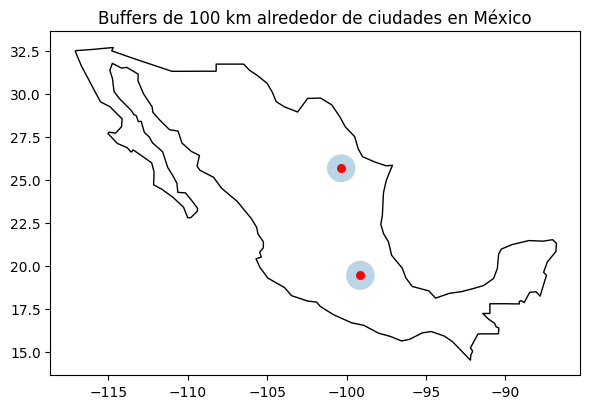

In [20]:
# Volver a coordenadas geográficas para graficar junto con el país
buf_geo    = buf_clip.to_crs(mex.crs)
sample_geo = sample_3857.to_crs(mex.crs)

# Mapa final
ax = mex.plot(figsize=(6,6), color="white", edgecolor="black")
buf_geo.plot(ax=ax, alpha=0.3)
sample_geo.plot(ax=ax, color="red", markersize=30)
ax.set_title("Buffers de 100 km alrededor de ciudades en México")
plt.tight_layout()


### 4) Qué observar
- El **join espacial** asigna correctamente las ciudades a México.  
- Con un CRS proyectado, los **buffers** quedan en kilómetros reales.  
- El **área** cambia si mides en geográficas; usa igual-área para reportes.

 ## **<font color="DodgerBlue"> Ejemplo geocientífico: Sismos recientes y su relación con límites de placas </font>**

Objetivo (≈25–35 min):
- Cargar **sismos reales** (USGS) y **límites de placas**.
- Calcular **distancia al límite de placa más cercano**.
- Mapear y hacer un recuento por país.

Qué verás:
- Lectura directa desde URLs.
- `GeoDataFrame`, CRS, `sjoin_nearest` y choropleth sencillo.

### Datos sísmicos del USGS en formato GeoJSON

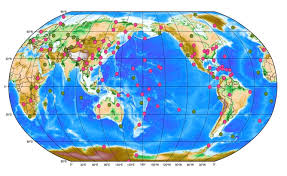

El **United States Geological Survey (USGS)** publica en tiempo real catálogos de sismos globales en distintos formatos.  
Uno de los más prácticos es **GeoJSON**, que combina datos tabulares con información geoespacial (latitud/longitud como geometrías).

---

In [21]:
# Sismos M>=4.5 del último mes (GeoJSON)
url_eq = "https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_month.geojson"
eq = gpd.read_file(url_eq)
eq

,id,mag,place,time,updated,tz,url,detail,felt,cdi,...,sources,types,nst,dmin,rms,gap,magType,type,title,geometry
0,us6000u2v8,5.2,off the coast of Ecuador,1792179250742,1792180524040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",60,6.629,1.20,141,mww,earthquake,M 5.2 - off the coast of Ecuador,POINT Z (-85.286 1.1718 10)
1,us6000u2qn,4.6,"41 km NNE of Kilimatinde, Tanzania",1792167445793,1792168537040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",26,4.281,1.02,125,mb,earthquake,"M 4.6 - 41 km NNE of Kilimatinde, Tanzania",POINT Z (35.1303 -5.524 10)
2,us6000u2qf,4.7,"186 km SSE of Vilyuchinsk, Russia",1792163327528,1792177628040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",34,2.039,1.05,128,mb,earthquake,"M 4.7 - 186 km SSE of Vilyuchinsk, Russia",POINT Z (159.5232 51.4073 10)
3,us6000u2qd,4.6,"153 km W of Neiafu, Tonga",1792163194084,1792164699040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",41,5.343,0.77,152,mb,earthquake,"M 4.6 - 153 km W of Neiafu, Tonga",POINT Z (-175.4291 -18.4686 247.722)
4,us6000u2q5,5.0,"Auckland Islands, New Zealand region",1792159794288,1792161175040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",49,4.319,1.26,63,mb,earthquake,"M 5.0 - Auckland Islands, New Zealand region",POINT Z (163.4041 -49.8826 10)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
619,us7000thxm,4.7,"28 km SW of Sipí, Colombia",1789592101454,1791573340040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",106,2.144,0.97,91,mb,earthquake,"M 4.7 - 28 km SW of Sipí, Colombia",POINT Z (-76.8196 4.4631 56.619)
620,us7000thxg,5.1,"190 km ESE of Kimbe, Papua New Guinea",1789590084473,1789765881040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",104,1.864,0.69,51,mb,earthquake,"M 5.1 - 190 km ESE of Kimbe, Papua New Guinea",POINT Z (151.7908 -6.0303 10)
621,us6000twwu,4.5,"25 km SW of Sipí, Colombia",1789589670623,1791569571040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,",us,",",origin,phase-data,",55,2.116,0.78,100,mb,earthquake,"M 4.5 - 25 km SW of Sipí, Colombia",POINT Z (-76.8127 4.4937 62.251)
622,us7000thxc,4.9,"24 km WSW of Sipí, Colombia",1789589572374,1789759985396,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,4.0,2.0,...,",us,",",dyfi,origin,phase-data,",153,2.088,0.50,67,mww,earthquake,"M 4.9 - 24 km WSW of Sipí, Colombia",POINT Z (-76.8399 4.5496 66.069)


### Límites de placas tectónicas (PB2002)

Además de fronteras políticas y ciudades, también podemos trabajar con **datos geológicos globales**.  
Un ejemplo clásico es el conjunto **PB2002** de Bird (2003), que contiene los principales **límites de placas tectónicas**.

---

Este archivo proviene de un repositorio de GitHub que recopila los límites de placas en formato GeoJSON.

Incluye segmentos de bordes de placas como líneas (LineString).

Cada segmento está etiquetado por tipo de límite:

Divergente (expansión, dorsales oceánicas).

Convergente (subducción, colisiones).

Transformante (fallas como San Andrés).

In [22]:
# Límites de placas (líneas, GeoJSON)
url_plates = "https://raw.githubusercontent.com/fraxen/tectonicplates/master/GeoJSON/PB2002_boundaries.json"
plates = gpd.read_file(url_plates)
plates

,LAYER,Name,Source,PlateA,PlateB,Type,geometry
0,plate boundary,AF-AN,Mueller et al. [1987],AF,AN,,"LINESTRING (-0.4379 -54.8518, -0.03883 -54.677..."
1,plate boundary,AF-AN,"by Peter Bird, October 2001",AF,AN,,"LINESTRING (7.77235 -54.396, 8.28834 -54.0326,..."
2,plate boundary,AN-AF,Lemaux et al. [2002],AN,AF,,"LINESTRING (32.1258 -46.9998, 31.8654 -47.2011..."
3,plate boundary,SO-AN,Lemaux et al. [2002],SO,AN,,"LINESTRING (32.1258 -46.9998, 33.1739 -47.2644..."
4,plate boundary,SO-AN,Mueller et al. [1987],SO,AN,,"LINESTRING (38.0827 -44.6188, 38.1937 -44.401,..."
...,...,...,...,...,...,...,...
236,plate boundary,CA\ND,Taboada et al. [1997],CA,ND,subduction,"LINESTRING (-76.684 8.7313, -76.7013 9.01654, ..."
237,plate boundary,CA\ND,Perez et al. [1997],CA,ND,subduction,"LINESTRING (-70.6594 13.3101, -70.4957 13.1623..."
238,plate boundary,ND-SA,Collot et al. [2002],ND,SA,,"LINESTRING (-81.5989 -3.24451, -81.3022 -3.267..."
239,plate boundary,ND-SA,Audemard and Audemard [2002],ND,SA,,"LINESTRING (-78.0055 0.14758, -77.707 0.58556,..."


In [23]:
# Campos útiles
eq["time"] = pd.to_datetime(eq["time"], unit="ms", errors="coerce")
eq = eq.to_crs("EPSG:4326")
plates = plates.to_crs(eq.crs)

print("Sismos cargados:", len(eq))
print("Límites de placa:", len(plates))

Sismos cargados: 624
Límites de placa: 241


### Distancia de los sismos a los límites de placas

Una aplicación típica en geociencias es calcular qué tan cerca está un sismo de un límite tectónico.  
Con `GeoPandas` podemos hacerlo con un *spatial join*.

---

#### 1. Unión espacial por cercanía
```python
near = gpd.sjoin_nearest(
    eq_m[["geometry"]],
    plates_m[["geometry"]],
    how="left",
    distance_col="dist_m"
)


In [24]:
# 2) Distancia al límite más cercano (en km)
eq_m     = eq.to_crs(3857)
plates_m = plates.to_crs(3857)

In [25]:
#Cálcula distancia de cada sismo y la geometría más cercana
near = gpd.sjoin_nearest(
    eq_m[["geometry"]],
    plates_m[["geometry"]],
    how="left",
    distance_col="dist_m"
)

In [26]:
near

,geometry,index_right,dist_m
0,POINT Z (-9493994.092 130453.274 10),59,9424.278491
1,POINT Z (3910687.107 -615883.742 10),225,401220.894900
2,POINT Z (17758041.394 6693659.086 10),68,89033.704013
3,POINT Z (-19528678.082 -2092470.97 247.722),91,54789.405787
4,POINT Z (18190061.206 -6425968.999 10),158,2173.501177
...,...,...,...
620,POINT Z (16897274.563 -672532.711 10),45,3212.424548
621,POINT Z (-8550750.65 500750.032 62.251),80,146033.653677
622,POINT Z (-8553778.541 506992.22 66.069),80,141559.463351
623,POINT Z (-19781985.584 -3502547.266 67.864),36,135643.050151


In [27]:
near.index.value_counts()

95     3
308    3
602    2
476    2
545    2
      ..
215    1
216    1
217    1
218    1
209    1
Name: count, Length: 624, dtype: int64

In [28]:
# Colapsa empates: una distancia (mínima) por índice de sismo
dist_km = (near["dist_m"]
           .groupby(near.index)   # índice del GeoDataFrame izquierdo (eq_m)
           .min()
           .rename("dist_km") / 1000.0)


In [29]:
dist_km

0        9.424278
1      401.220895
2       89.033704
3       54.789406
4        2.173501
          ...    
619    146.216312
620      3.212425
621    146.033654
622    141.559463
623    135.643050
Name: dist_km, Length: 624, dtype: float64

In [31]:
# Alinea por índice y agrega a eq
eq = eq.join(dist_km)
eq["near_plate"] = eq["dist_km"] <= 100.0

In [33]:
eq.head()

,id,mag,place,time,updated,tz,url,detail,felt,cdi,...,nst,dmin,rms,gap,magType,type,title,geometry,dist_km,near_plate
0,us6000u2v8,5.2,off the coast of Ecuador,2026-10-16 19:34:10.742,1792180524040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,60,6.629,1.20,141,mww,earthquake,M 5.2 - off the coast of Ecuador,POINT Z (-85.286 1.1718 10),9.424278,True
1,us6000u2qn,4.6,"41 km NNE of Kilimatinde, Tanzania",2026-10-16 16:17:25.793,1792168537040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,26,4.281,1.02,125,mb,earthquake,"M 4.6 - 41 km NNE of Kilimatinde, Tanzania",POINT Z (35.1303 -5.524 10),401.220895,False
2,us6000u2qf,4.7,"186 km SSE of Vilyuchinsk, Russia",2026-10-16 15:08:47.528,1792177628040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,34,2.039,1.05,128,mb,earthquake,"M 4.7 - 186 km SSE of Vilyuchinsk, Russia",POINT Z (159.5232 51.4073 10),89.033704,True
3,us6000u2qd,4.6,"153 km W of Neiafu, Tonga",2026-10-16 15:06:34.084,1792164699040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,41,5.343,0.77,152,mb,earthquake,"M 4.6 - 153 km W of Neiafu, Tonga",POINT Z (-175.4291 -18.4686 247.722),54.789406,True
4,us6000u2q5,5.0,"Auckland Islands, New Zealand region",2026-10-16 14:09:54.288,1792161175040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,...,49,4.319,1.26,63,mb,earthquake,"M 5.0 - Auckland Islands, New Zealand region",POINT Z (163.4041 -49.8826 10),2.173501,True


`sjoin_nearest` busca, para cada sismo (`eq_m`), el segmento de límite más cercano en plates_m.

Guarda la distancia en una nueva columna dist_m (en metros, porque usamos CRS proyectado EPSG:3857).

Puede haber empates si un sismo está equidistante a dos segmentos.

Para cada sismo, tomamos la distancia mínima. `min`

Convertimos de metros a kilómetros.

### Mapa rápido

Pintamos los sismos: círculos más oscuros si están cerca de un límite de placa.

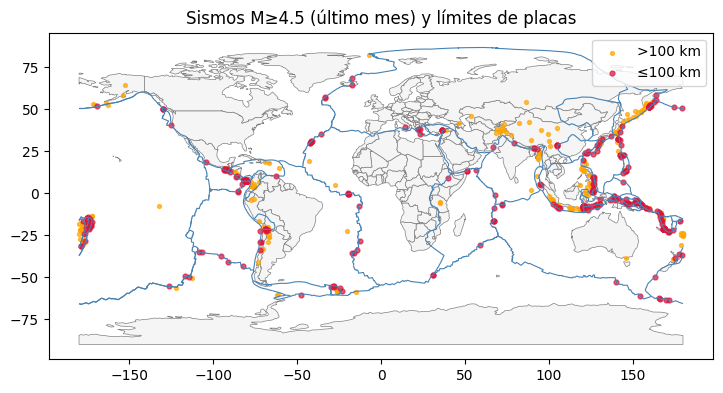

In [34]:
fig, ax = plt.subplots(figsize=(8,4))
world.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.5)
plates.plot(ax=ax, color="steelblue", linewidth=0.8)
# dividmos en dos grupos, cercanos y lejanos a los 100 km
eq_close = eq[eq["near_plate"]]
eq_far   = eq[~eq["near_plate"]]

eq_far.plot(ax=ax, markersize=8, color="orange", alpha=0.7, label=">100 km")
eq_close.plot(ax=ax, markersize=12, color="crimson", alpha=0.7, label="≤100 km")

ax.set_title("Sismos M≥4.5 (último mes) y límites de placas")
ax.legend()
plt.tight_layout()

### Sismos por país con *spatial join*

Una vez que tenemos los sismos en un `GeoDataFrame`, podemos preguntarnos:  
👉 ¿En qué país cayó cada evento?

---

`sjoin` combina dos capas: sismos (puntos) y países (polígonos).

Con `predicate="within"` buscamos qué punto está dentro de qué polígono.

El resultado añade la columna `"ADMIN"` (nombre del país) a cada sismo.

`how="left"` asegura que mantenemos todos los sismos, aunque alguno quede fuera de los polígonos.

In [35]:
# 3) Join espacial sismos→países
eq_countries = gpd.sjoin(
    eq[["geometry","mag","place","time"]].to_crs(world.crs),
    world[["ADMIN","geometry"]],
    how="left",
    predicate="within"
)
eq_countries

,geometry,mag,place,time,index_right,ADMIN
0,POINT Z (-85.286 1.1718 10),5.2,off the coast of Ecuador,2026-10-16 19:34:10.742,NaN,NaN
1,POINT Z (35.1303 -5.524 10),4.6,"41 km NNE of Kilimatinde, Tanzania",2026-10-16 16:17:25.793,1.0,United Republic of Tanzania
2,POINT Z (159.5232 51.4073 10),4.7,"186 km SSE of Vilyuchinsk, Russia",2026-10-16 15:08:47.528,NaN,NaN
3,POINT Z (-175.4291 -18.4686 247.722),4.6,"153 km W of Neiafu, Tonga",2026-10-16 15:06:34.084,NaN,NaN
4,POINT Z (163.4041 -49.8826 10),5.0,"Auckland Islands, New Zealand region",2026-10-16 14:09:54.288,NaN,NaN
...,...,...,...,...,...,...
619,POINT Z (-76.8196 4.4631 56.619),4.7,"28 km SW of Sipí, Colombia",2026-09-16 20:55:01.454,32.0,Colombia
620,POINT Z (151.7908 -6.0303 10),5.1,"190 km ESE of Kimbe, Papua New Guinea",2026-09-16 20:21:24.473,NaN,NaN
621,POINT Z (-76.8127 4.4937 62.251),4.5,"25 km SW of Sipí, Colombia",2026-09-16 20:14:30.623,32.0,Colombia
622,POINT Z (-76.8399 4.5496 66.069),4.9,"24 km WSW of Sipí, Colombia",2026-09-16 20:12:52.374,32.0,Colombia


In [37]:
# contamos por cada pais el numero de sismos
counts = eq_countries.groupby("ADMIN", dropna=True).size().rename("n_eq").reset_index()
counts

,ADMIN,n_eq
0,Afghanistan,2
1,Argentina,4
2,Australia,1
3,Azerbaijan,1
4,Bhutan,2
5,Bolivia,2
6,Chile,8
7,China,12
8,Colombia,17
9,Dominican Republic,1


In [38]:
world

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,None,None,None,None,None,None,None,None,None,"POLYGON ((18.82982 45.90887, 18.82984 45.90888..."
173,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,None,None,None,None,None,None,None,None,None,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,..."
174,Admin-0 country,1,6,Kosovo,KOS,0,2,Disputed,1,Kosovo,...,Admin-0 country,Unrecognized,Admin-0 country,Unrecognized,Admin-0 country,Admin-0 country,Admin-0 country,Admin-0 country,Unrecognized,"POLYGON ((20.59025 41.85541, 20.52295 42.21787..."
175,Admin-0 country,1,5,Trinidad and Tobago,TTO,0,2,Sovereign country,1,Trinidad and Tobago,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-61.68 10.76, -61.105 10.89, -60.895..."


In [43]:
# unir con el mapa mundial
world_eq = world.merge(counts, on="ADMIN", how="left")#.fillna({"n_eq":0})
world_eq

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry,n_eq
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ...",NaN
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",2.0
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948...",NaN
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",NaN
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312...",2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,None,None,None,None,None,None,None,None,"POLYGON ((18.82982 45.90887, 18.82984 45.90888...",NaN
173,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,None,None,None,None,None,None,None,None,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,...",NaN
174,Admin-0 country,1,6,Kosovo,KOS,0,2,Disputed,1,Kosovo,...,Unrecognized,Admin-0 country,Unrecognized,Admin-0 country,Admin-0 country,Admin-0 country,Admin-0 country,Unrecognized,"POLYGON ((20.59025 41.85541, 20.52295 42.21787...",NaN
175,Admin-0 country,1,5,Trinidad and Tobago,TTO,0,2,Sovereign country,1,Trinidad and Tobago,...,None,None,None,None,None,None,None,None,"POLYGON ((-61.68 10.76, -61.105 10.89, -60.895...",NaN


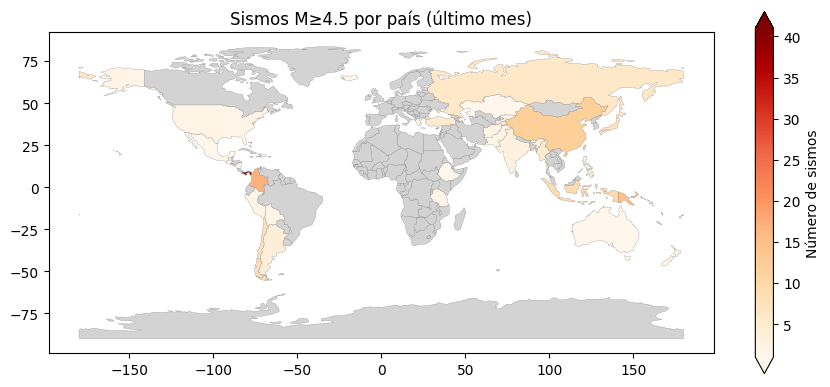

               ADMIN  n_eq
24            Panama    41
8           Colombia    17
25  Papua New Guinea    15
7              China    12
15         Indonesia     9
6              Chile     8
16             Japan     7
28            Russia     6
20           Myanmar     5
30            Turkey     5


In [44]:
# Mapa coroplético
fig, ax = plt.subplots(figsize=(9,4))
world_eq.plot(column="n_eq", ax=ax, legend=True, cmap="OrRd",
              edgecolor="gray", linewidth=0.2, missing_kwds={"color":"lightgray"},
             legend_kwds={"label": "Número de sismos", "extend":"both"})
ax.set_title("Sismos M≥4.5 por país (último mes)")
plt.tight_layout(); plt.show()

# Vista rápida de top-10
top10 = counts.sort_values("n_eq", ascending=False).head(10)
print(top10)

#GeoPandas es suficiente para colorear los países y mostrar sus datos. 
#Cartopy es especialmente útil si quieres controlar la proyección, agregar una cuadrícula de latitud y longitud con etiquetas geográficas


### Guía: Lagos por país con GeoPandas (Natural Earth)

Objetivo: cargar lagos y países, asignar cada lago a un país con un join espacial, contar lagos por país y mapear el resultado.

---

#### Paso 1. Carga los datos de lagos (puntos)
- Lee el dataset de Natural Earth (10m):  
  `https://naciscdn.org/naturalearth/10m/physical/ne_10m_lakes.zip`
- Guarda el resultado en un GeoDataFrame llamado `lakes`.

Sugerencia: revisa columnas disponibles y el `crs` con `lakes.head()` y `lakes.crs`.

---



#### Paso 2.  Reproyecta a un CRS igual-área global (p. ej., EPSG:6933) para que las áreas salgan en m² coherentes.

Sugerencia: confirma que existe la columna `ADMIN` (nombre oficial del país).

---

### Paso 3 — Intersección espacial

Usa `gpd.overlay(lagos, países, how="intersection")` para recortar cada polígono de lago al país donde cae (si cruza fronteras, se parte).


### Paso 4 — Área y agregación

Calcula area_km2 = geometry.area / 1e6 en la capa intersectada.

Agrupa por ADMIN (nombre del país) y suma area_km2 → obtén una tabla area_lagos_por_pais.

### Paso 5 — Unir y mapear

Haz un merge de la tabla de áreas al GeoDataFrame de países.

Mapa coroplético con column="area_lagos_km2", paleta legible (p. ej., "Blues"), leyenda y bordes sutiles.

(Opcional) Superpone los contornos de lagos para referencia.

### Paso 6 — Preguntas rápidas y adicionales

¿Qué países concentran más área de lagos? Muestra el top 10.

¿Cómo cambian los resultados si usas un CRS que no es igual-área?

Filtra solo América y repite; compara con el mundo.